# Контрольная работа №1
Работа сдается в гугл-форму, которая будет закреплена в telegram конференции группы

Работа при сдаче в гугл форму должна называться КР_Фамилия_Имя_Отчество.zip

Перед сдачей просьба не стирать вывод ячеек для того, чтобы преподаватель заново не запускал ваш код

 # Практическое задание: обработка и распознавание речи

1. **Запись.** Запишите с помощью Python три звуковых семпла длиной от 7 до 20 секунд:
    - `phrase.wav` — законченная фраза, произнесённая вами (цензурная, пожалуйста 🙃️️️️). Запишите в ноутбук её точный текст: он понадобится в п. 6;
    - Для дальнейшего выполнения работы будет проще, если фраза будет на английском. Но если сможете реализовать задание на русской фразе, то от меня будет бонус
    - `sample_1.wav`, `sample_2.wav` — что угодно на ваш выбор.

    *Как записать:* в Colab используйте код записи через браузер из ноутбука «Работа со звуком», локально — библиотеку `sounddevice`.
<br><br>

2. **Признаки.** Для каждого фрагмента постройте:
    - временной график сигнала;
    - амплитудный спектр (БПФ);
    - спектрограмму (STFT);
    - мел-спектрограмму.
    - Кратко опишите, чем фрагменты различаются на этих графиках.
<br><br>
3. **Шумоочистка.** Добавьте к одному из семплов шум (или запишите его в шумном месте). Выберите **один** из способов очистки, разобранных в курсе. Примените его. Покажите спектрограммы «до» и «после» и посчитайте ошибку (MSE или SNR) относительно чистой записи.
<br><br>
4. **Переозвучка.** Возьмите образец речи другого человека: запишите знакомого, возьмите запись из открытого датасета, например LibriSpeech, или найдите семпл голоса какой-либо иной персоны в интрнете (если что, без согласия так делать нехорошо, незаконно и а-та-та. Но я не против). Переозвучьте свою фразу его голосом. Сохраните в `phrase_converted.wav`
<br><br>
5. **Распознавание.** Распознайте речь в `phrase.wav` и `phrase_converted.wav`. Посчитайте для обеих записей **CER** (долю ошибок в символах) относительно правильного текста фразы. Изменилось ли качество распознавания? Почему?  
    - модель из ноутбука распознаёт только английскую речь, в этом нюанс. Если сможете найти подходящую для русской речи модель и сами её запустить - будете молодцы)
    
    *Дополнительно:* повторите на нескольких фразах или посчитайте близость голосовых эмбеддингов исходной и переозвученной записи.
<br><br>

6. **Сохранение.** Сохраните результаты в `.wav`:
    - `phrase.wav`, `sample_2.wav`, `sample_3.wav` — исходные записи;
    - `sample_denoised.wav` — фраза после очистки;
    - `phrase_converted.wav` — фраза из п. 4.
<br><br>    
7. **Сдача.** Приложите `.zip`-архив с ноутбуком и пятью `.wav`-файлами из п. 6.

> **Не стирайте вывод ячеек** перед сдачей, чтобы преподавателю не пришлось запускать ваш код заново.

### P.S.S У вас всё получится, удачи :)

# Решение

## Запись/загрузка сэмплов

In [1]:
!pip install -q ffmpeg-python librosa

Копируем функцию для доступа к микрофону из колаб.

In [2]:
from IPython.display import HTML, Audio # библиотеки для работы с HTML и воспроизведения звука
from google.colab.output import eval_js # для выполнения Javascript
from base64 import b64decode # для конвертирования звука в подходящий формат
import numpy as np
from scipy.io.wavfile import read as wav_read # для чтения wav файлов
import io # ввод\вывод
import ffmpeg # для работы с mpeg

#  код для получения записи микрофона в браузере
AUDIO_HTML = """
<script>
var my_div = document.createElement("DIV");
var my_p = document.createElement("P");
var my_btn = document.createElement("BUTTON"); // кнопка начала записи
var t = document.createTextNode("Press to start recording"); // текст кнопки начала записи

my_btn.appendChild(t);
my_div.appendChild(my_btn);
document.body.appendChild(my_div);

var base64data = 0;
var reader;
var recorder, gumStream;
var recordButton = my_btn;

// функция для создания потока аудио
var handleSuccess = function(stream) {
  gumStream = stream;
  var options = {
    //bitsPerSecond: 8000, //chrome seems to ignore, always 48k
    mimeType : 'audio/webm;codecs=opus'
    //mimeType : 'audio/webm;codecs=pcm'
  };

  recorder = new MediaRecorder(stream); // интерфейс для записи
  recorder.ondataavailable = function(e) {
    var url = URL.createObjectURL(e.data);
    var preview = document.createElement('audio');
    preview.controls = true;
    preview.src = url;
    document.body.appendChild(preview);

    reader = new FileReader();
    reader.readAsDataURL(e.data);
    reader.onloadend = function() {
      base64data = reader.result;
      //console.log("Inside FileReader:" + base64data);
    }
  };
  recorder.start(); //начинаем запись
  };

recordButton.innerText = "Recording... press to stop"; // меняем текст кнопки

navigator.mediaDevices.getUserMedia({audio: true}).then(handleSuccess);

// включение\выключение записи
function toggleRecording() {
  if (recorder && recorder.state == "recording") {
      recorder.stop(); // останавливаем запись
      gumStream.getAudioTracks()[0].stop();
      recordButton.innerText = "Saving the recording... pls wait!" // меняем текст кнопки
  }
}

// https://stackoverflow.com/a/951057

// пауза
function sleep(ms) {
  return new Promise(resolve => setTimeout(resolve, ms));
}

// эти данные будут отправляться в Python
var data = new Promise(resolve=>{
recordButton.onclick = ()=>{
toggleRecording()

sleep(2000).then(() => {
  // ждем 2000ms доступности данных...

  resolve(base64data.toString())

});

}
});

</script>
"""
# функция получения записи
def get_audio():
  display(HTML(AUDIO_HTML)) # создаем HTML
  data = eval_js("data") # выполняем
  binary = b64decode(data.split(',')[1]) # переводим в байтовый вид
  # обработка
  process = (ffmpeg
    .input('pipe:0')
    .output('pipe:1', format='wav')
    .run_async(pipe_stdin=True, pipe_stdout=True, pipe_stderr=True, quiet=True, overwrite_output=True)
  )
  output, err = process.communicate(input=binary)
  # байты надо расставить в правильном порядке для Wav
  riff_chunk_size = len(output) - 8
  # Break up the chunk size into four bytes, held in b.
  q = riff_chunk_size
  b = []
  for i in range(4):
      q, r = divmod(q, 256)
      b.append(r)

  # Replace bytes 4:8 in proc.stdout with the actual size of the RIFF chunk.
  riff = output[:4] + bytes(b) + output[8:]

  # читаем в Wav из буфера
  sr, audio = wav_read(io.BytesIO(riff))
  # sr - частота дискретизации
  # audio - звук в формате Wav.
  return audio, sr

Запись голоса делал через функцию ниже, но она закомментирована так как все нужные образцы голоса предоставлены в архиве.

In [3]:
#audio, sr = get_audio()

In [4]:
#import scipy
#scipy.io.wavfile.write('sample_rus.wav', sr, audio) # записываем в файл

In [5]:
#Audio(audio, rate=sr)

phrase.wav = "You are now under examination conditions.
It is not allowed to start the exam on Smart LMS without being verified . It is not allowed to use or to have ANY electronic devices (including smart watches) during the Exam.
" (моя озвучка)

sample_1.wav - текст из phrase.wav (озвученный TTS-моделью).

sample_2.wav = "The data is flowing, analytics started! Real-time insights are now available. Watch as the numbers tell their story." (моя озвучка)

## Визуализация звука

In [6]:
import librosa
import matplotlib.pyplot as plt

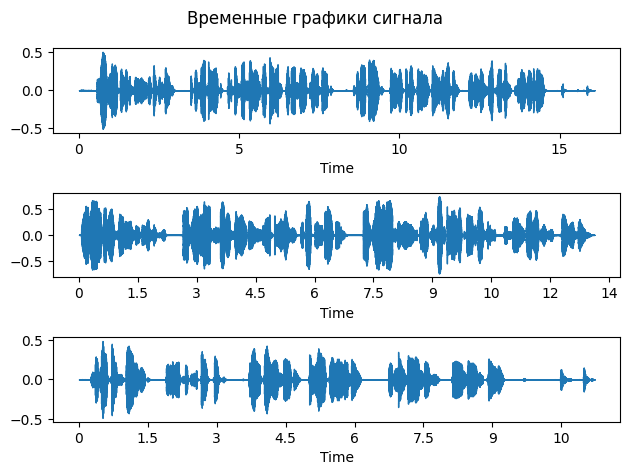

In [7]:
filename1 = 'recording.wav'
filename2 = 'sample_1.wav'
filename3 = 'sample_2.wav'

fig, ax = plt.subplots(nrows=3)

data1,sample_rate1 = librosa.load(filename1,
                                  sr=22050,
                                  #sr=44100,
                                  mono=True,
                                  offset=0.0,
                                  duration=200,
                                  res_type='scipy')

data2,sample_rate2 = librosa.load(filename2,
                                  sr=22050,
                                  #sr=44100,
                                  mono=True,
                                  offset=0.0,
                                  duration=200,
                                  res_type='scipy')

data3,sample_rate3 = librosa.load(filename3,
                                  sr=22050,
                                  #sr=44100,
                                  mono=True,
                                  offset=0.0,
                                  duration=200,
                                  res_type='scipy')

plt.suptitle('Временные графики сигнала')
librosa.display.waveshow(data1, sr=sample_rate1, ax=ax[0])
librosa.display.waveshow(data2, sr=sample_rate2, ax=ax[1])
librosa.display.waveshow(data3, sr=sample_rate3, ax=ax[2])
plt.tight_layout()

Звуковая волна отражает амплитуду звука в зависимости от времени. График сигнала у текста, озвученного TTS, не имеет небольших выбросов во время пауз, в отличие от собственной записи. Голос TTS также меньше "скачет".

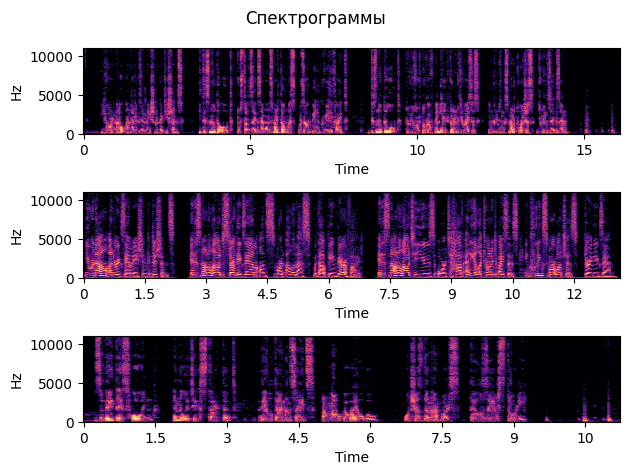

In [8]:
fig, ax = plt.subplots(nrows=3)
plt.suptitle('Спектрограммы')

D1 = librosa.amplitude_to_db(np.abs(librosa.stft(data1)), ref=np.max)
img1 = librosa.display.specshow(D1, sr=sample_rate1, x_axis='time', y_axis='hz', ax=ax[0])

D2 = librosa.amplitude_to_db(np.abs(librosa.stft(data2)), ref=np.max)
img2 = librosa.display.specshow(D2, sr=sample_rate2, x_axis='time', y_axis='hz', ax=ax[1])

D3 = librosa.amplitude_to_db(np.abs(librosa.stft(data3)), ref=np.max)
img3 = librosa.display.specshow(D3, sr=sample_rate3, x_axis='time', y_axis='hz', ax=ax[2])
plt.tight_layout()

Спектрограммы более информативны показывают энергию частотных компонентов во времени.

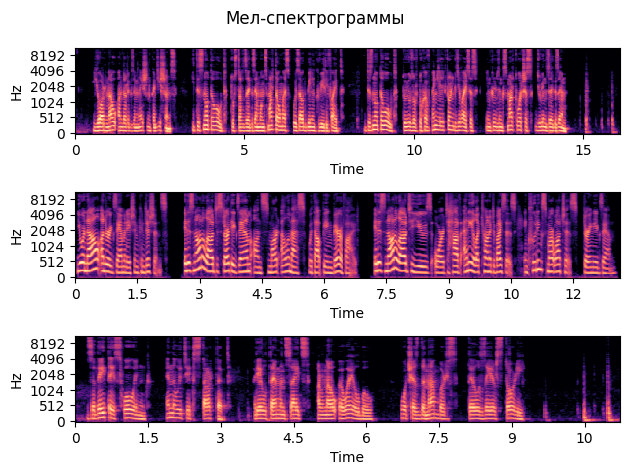

In [9]:
fig, ax = plt.subplots(nrows=3)
plt.suptitle('Мел-спектрограммы')

mel_spec_1 = librosa.feature.melspectrogram(y=data1, sr=sample_rate1, n_mels=128)
mel_spec_db_1 = librosa.power_to_db(mel_spec_1, ref=np.max)
img_1 = librosa.display.specshow(mel_spec_db_1, sr=sample_rate1, x_axis='time', y_axis='mel', ax=ax[0])

mel_spec_2 = librosa.feature.melspectrogram(y=data2, sr=sample_rate2, n_mels=128)
mel_spec_db_2 = librosa.power_to_db(mel_spec_2, ref=np.max)
img_2 = librosa.display.specshow(mel_spec_db_2, sr=sample_rate2, x_axis='time', y_axis='mel', ax=ax[1])

mel_spec_3 = librosa.feature.melspectrogram(y=data3, sr=sample_rate3, n_mels=128)
mel_spec_db_3 = librosa.power_to_db(mel_spec_3, ref=np.max)
img_3 = librosa.display.specshow(mel_spec_db_3, sr=sample_rate3, x_axis='time', y_axis='mel', ax=ax[2])
plt.tight_layout()

Мел-спектрограммы приближают отображение звука к восприятию человеческим ухом. Слова различимы по виду графика. На мел-спектрограмме моей записи гармоники менее чёткие, энергия сосредоточена в низких частотах, а в паузах остаётся фоновый шум. У TTS-озвучки гармоники ярче и с выраженными изгибами (интонация), много энергии в высоких частотах на согласных, а паузы чистые и короткие. Слова и слоги различимы на обеих спектрограммах, у TTS границы чётче.

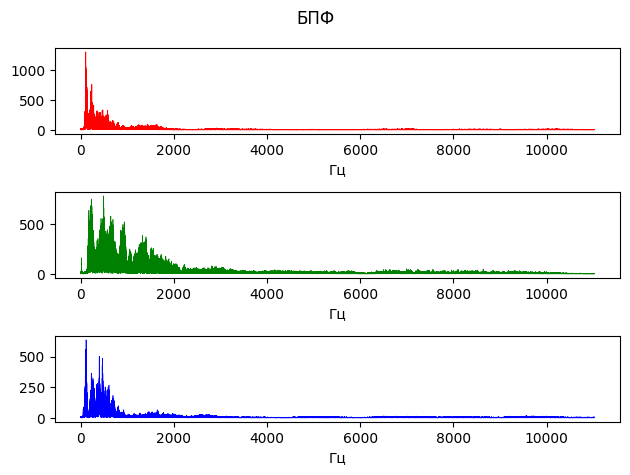

In [10]:
fig, ax = plt.subplots(nrows=3)
plt.suptitle('БПФ')

fft_data_1 = np.fft.rfft(data1)
amplitude_spectrum_1 = np.abs(fft_data_1)
frequencies_fft_1 = np.fft.rfftfreq(len(data1), 1/sample_rate1)

fft_data_2 = np.fft.rfft(data2)
amplitude_spectrum_2 = np.abs(fft_data_2)
frequencies_fft_2 = np.fft.rfftfreq(len(data2), 1/sample_rate2)

fft_data_3 = np.fft.rfft(data3)
amplitude_spectrum_3 = np.abs(fft_data_3)
frequencies_fft_3 = np.fft.rfftfreq(len(data3), 1/sample_rate3)

ax[0].plot(frequencies_fft_1, amplitude_spectrum_1, color='red', linewidth=0.5)
ax[0].set_xlabel("Гц")
ax[1].plot(frequencies_fft_2, amplitude_spectrum_2, color='green', linewidth=0.5)
ax[1].set_xlabel("Гц")
ax[2].plot(frequencies_fft_3, amplitude_spectrum_3, color='blue', linewidth=0.5)
ax[2].set_xlabel("Гц")
plt.tight_layout()

Здесь получили частотное представление всего фрагмента вне зависимости от времени. У TTS-озвучки энергия распределена шире, с несколькими пиками и заметными высокочастотными компонентами.

## Добавление шума

Тут может быть громко, советую убавить звук при прослушивании (оно не включается автоматически)

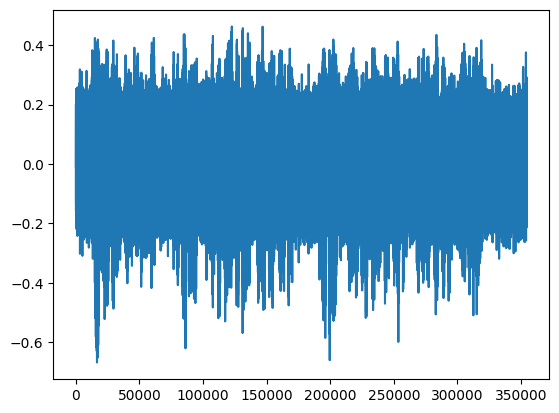

In [11]:
import numpy as np
import IPython
import IPython.display as ipd

H=0.08
noise=np.random.normal(0, H, data1.shape[0])
signal_noise = data1 + noise
plt.plot(signal_noise)
ipd.Audio(signal_noise,rate=sample_rate1)

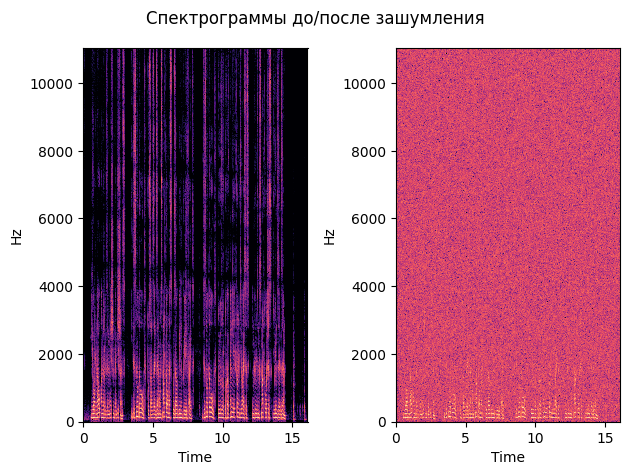

In [12]:
fig, ax = plt.subplots(ncols=2)

plt.suptitle("Спектрограммы до/после зашумления")
D1_noised = librosa.amplitude_to_db(np.abs(librosa.stft(signal_noise)), ref=np.max)

librosa.display.specshow(D1, sr=sample_rate1, x_axis='time', y_axis='hz', ax=ax[0])
librosa.display.specshow(D1_noised, sr=sample_rate1, x_axis='time', y_axis='hz', ax=ax[1])
plt.tight_layout()

На первой спектрограмме видны структуры речи, в то время как вторая спектрограмма имеет практически равномерное распределение энергии по частотам

In [13]:
!pip install -q padasip

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Для очистки использовал адаптивный фильтр GNGD: n=256, mu=0.05, eps=0.001. Шум гауссов, σ=0.08, добавлен к phrase.wav

In [14]:
SAMPLERATE = 22050
n = 256

In [15]:
import padasip as pa

signal_noise_f = pa.input_from_history(signal_noise, n)
data1_f = data1[n-1:]

f = pa.filters.FilterGNGD(n=n, mu=0.05, eps=0.001, w="zeros")
yp, e, w = f.run(data1_f, signal_noise_f)

In [16]:
print("Original record:")
IPython.display.display(Audio(data1, rate=SAMPLERATE))

print("Distorted record:")
IPython.display.display(Audio(signal_noise, rate=SAMPLERATE))

print("Enhanced record")
IPython.display.display(Audio(yp, rate=SAMPLERATE))

Original record:


Distorted record:


Enhanced record


In [17]:
from scipy.io import wavfile
wavfile.write('sample_denoised.wav', SAMPLERATE, yp.astype(np.float32))

Фильтр смог снизить количество шума и сделать полезный сигнал более явным, но качество далеко от идеала для данного фильтра и его настроек.

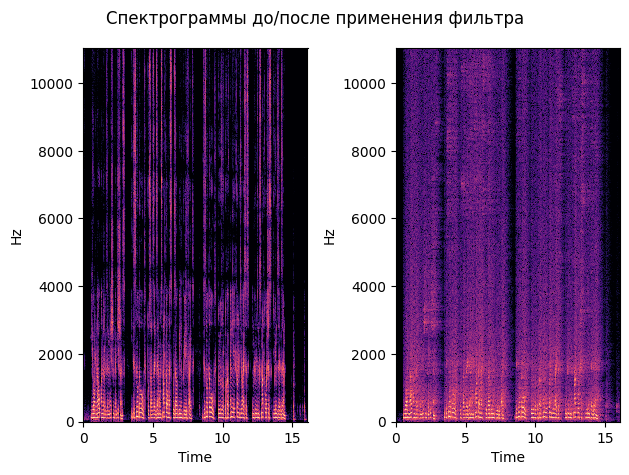

In [18]:
fig, ax = plt.subplots(ncols=2)

e_spec = librosa.amplitude_to_db(np.abs(librosa.stft(yp)), ref=np.max)

plt.suptitle("Спектрограммы до/после применения фильтра")
librosa.display.specshow(D1, sr=sample_rate1, x_axis='time', y_axis='hz', ax=ax[0])
librosa.display.specshow(e_spec, sr=sample_rate1, x_axis='time', y_axis='hz', ax=ax[1])
plt.tight_layout()

Структуры речи видны в отличие от полностью зашумленного сигнала, но качество далеко от идеала как уже ранее говорилось.

In [19]:
clean = data1[n-1:]
mse_before = np.mean((clean - signal_noise[n-1:])**2)
mse_after = np.mean((clean - yp)**2)
snr = lambda s, x: 10*np.log10(np.sum(s**2) / np.sum((s - x)**2))
print(f"MSE до: {mse_before:.6f}, после: {mse_after:.6f}")
print(f"SNR до: {snr(clean, signal_noise[n-1:]):.2f} дБ, после: {snr(clean, yp):.2f} дБ")

MSE до: 0.006405, после: 0.000508
SNR до: -1.85 дБ, после: 9.16 дБ


Получаем выигрыш около 11 дБ по сравнению с зашумленной версией. MSE нового сигнала почти в 13 раз меньше зашумленного. Для комфортного прослушивания нужно еще фильтровать сигнал, но очистка уже работает.

# Переозвучка и сравнение голосовых эмбеддингов

Для переозвучки брал сэмпл TTS-Голоса для телефонии (Александра)

In [20]:
%pip -q install chatterbox-tts "torchvision==0.21.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you have starlette 0.52.1 which is incompatible.
python-fasthtml 0.14.14 requires starlette>=1.0.1, but you have starlette 0.52.1 which is incompatible.


In [21]:
import os
import urllib.request
import numpy as np
import torch
import torchaudio
from IPython.display import Audio, display

from chatterbox.mtl_tts import ChatterboxMultilingualTTS
from chatterbox.vc import ChatterboxVC

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Устройство:", DEVICE)

/usr/local/lib/python3.13/dist-packages/perth/perth_net/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Устройство: cuda


In [22]:
model = ChatterboxMultilingualTTS.from_pretrained(device=DEVICE)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/models/lora.py:393: FutureWarning: `LoRACompatibleLinear` is deprecated and will be removed in version 1.0.0. Use of `LoRACompatibleLinear` is deprecated. Please switch to PEFT backend by installing PEFT: `pip install peft`.
  deprecate("LoRACompatibleLinear", "1.0.0", deprecation_message)


Cangjie5_TC.json:   0%|          | 0.00/1.92M [00:00<?, ?B/s]

Downloading: "https://github.com/explosion/spacy-pkuseg/releases/download/v0.0.26/spacy_ontonotes.zip" to /root/.pkuseg/spacy_ontonotes.zip
100%|██████████| 34567143/34567143 [00:00<00:00, 128086862.55it/s]


loaded PerthNet (Implicit) at step 250,000


In [23]:
!pip install -q resampy

In [24]:
voice_sample_path = "alexandra.wav"

text_to_speak = """You are now under examination conditions.
It is not allowed to start the exam on Smart LMS without being verified.
It is not allowed to use or to have ANY electronic devices (including smart watches) during the Exam. """

def synthesize(text, voice_path, language="en", **kwargs):
    wav = model.generate(text, language_id=language, audio_prompt_path=voice_path, **kwargs)
    display(Audio(wav.squeeze(0).numpy(), rate=model.sr))
    return wav

clone_en = synthesize(text_to_speak, voice_sample_path, language="en")


/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
The following generation flags are not valid and may be ignored: ['output_attentions']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Sampling:  28%|██▊       | 284/1000 [00:20<00:50, 14.13it/s]


In [25]:
display(Audio(clone_en.squeeze(0).numpy(), rate=model.sr))

import torchaudio
torchaudio.save("phrase_converted.wav", clone_en, model.sr)

In [26]:
def voice_embedding(path):
    wav, _ = librosa.load(path, sr=16000)
    emb = model.ve.embeds_from_wavs([wav], sample_rate=16000, as_spk=True)
    return np.asarray(emb).ravel()

def cos_sim(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

emb_orig = voice_embedding('recording.wav')
emb_conv = voice_embedding('phrase_converted.wav')
emb_target = voice_embedding(voice_sample_path)

print("Мой голос vs клон: ", cos_sim(emb_orig, emb_conv))
print("Целевой голос vs клон: ", cos_sim(emb_target, emb_conv))
print("Мой голос vs целевой: ", cos_sim(emb_orig, emb_target))

Мой голос vs клон:  0.6573541164398193
Целевой голос vs клон:  0.8657906651496887
Мой голос vs целевой:  0.6433287858963013


Целевой голос (Alexandra) в значительной степени похож на его клон. Клонирование прошло успешно. В то же время мой голос не похож ни на Alexandra, ни на клон ее голоса, что логично.

# Распознавание

In [27]:
!pip -q install transformers

In [28]:
from transformers import Wav2Vec2Processor, Wav2Vec2ForCTC

In [29]:
tokenizer = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
model = Wav2Vec2ForCTC.from_pretrained("facebook/wav2vec2-base-960h")

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [30]:
def recognize_speech(path):
  input_audio, _ = librosa.load(path, sr=16000)

  input_values = tokenizer(input_audio, return_tensors="pt", padding="longest").input_values

  with torch.no_grad():
    logits = model(input_values).logits
    predicted_ids = torch.argmax(logits, dim=-1)

  transcription = tokenizer.batch_decode(predicted_ids)[0]
  return transcription

In [31]:
reference = """You are now under examination conditions.
It is not allowed to start the exam on Smart LMS without being verified .
It is not allowed to use or to have ANY electronic devices (including smart watches) during the Exam."""

speech_ref = recognize_speech('recording.wav')
speech_cloned = recognize_speech('phrase_converted.wav')

It is strongly recommended to pass the `sampling_rate` argument to `Wav2Vec2FeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.
It is strongly recommended to pass the `sampling_rate` argument to `Wav2Vec2FeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.


In [32]:
speech_ref, speech_cloned

('YOU ARE NOW UNDER EXAMINATION CONDITIONS IT IS NOT A OT TO START THE EXAMINE MARTOMAS WITHOUT BEING REALIFIED IT IS NOT A OT TO USE ORE TO HAVE ANY ELECTRONIC DEVICES INCLUDING SMART WATCHES DURING THE EXAMNE',
 'YOU ARE NOW UNDER EXAMINATION CONDITIONS IT IS NOT ALLOWED TO START THE EXAMINE SMART ALLAMS WITHOUT BEING VERIFIED IT IS NOT ALLOWED TO USE OR TO HAVE ANY ELECTRONIC DEVICES INCLUDING SMART WATCHES DURING THE EXAM')

In [33]:
!pip -q install jiwer

In [34]:
import jiwer
import re
def norm(s):
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", "", s.lower())).strip()

cer_ref = jiwer.cer(norm(reference), norm(speech_ref))
cer_cloned = jiwer.cer(norm(reference), norm(speech_cloned))

In [35]:
print(f"CER Оригинала: {cer_ref}, CER Клонированного голоса: {cer_cloned}")

CER Оригинала: 0.10900473933649289, CER Клонированного голоса: 0.02843601895734597


Качество распознавания склонированного голоса лучше, чем у оригинала. Вероятно, у склонированного голоса более четкая дикция, потому правильно распознаны сложные слова в духе allowed/verified.

In [36]:
tokenizer = Wav2Vec2Processor.from_pretrained("bond005/wav2vec2-large-ru-golos-with-lm")
model = Wav2Vec2ForCTC.from_pretrained("bond005/wav2vec2-large-ru-golos-with-lm")

preprocessor_config.json:   0%|          | 0.00/262 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.28k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/522 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

In [37]:
russian_wav2vec = recognize_speech('sample_rus.wav')
russian_wav2vec

It is strongly recommended to pass the `sampling_rate` argument to `Wav2Vec2FeatureExtractor()`. Failing to do so can result in silent errors that might be hard to debug.


'раз два три я слышно я записываю русский семпл голоса для того чтобы распознать его русскоязычной в автоувек моделью все'

In [38]:
rus_ref = "раз два три я слышно я записываю русский семпл голоса для того чтобы распознать его русскоязычной wav2vec-моделью. все"
rus_cer_ref = jiwer.cer(norm(rus_ref), norm(russian_wav2vec))
print(f"CER распознанного голоса: {rus_cer_ref}")

CER распознанного голоса: 0.09482758620689655


Работать с голосами на русском можно при помощи любой русскоязычной wav2vec-модели с hf. Пример выше.